# BAGIAN 1. LINGKUNGAN KERJA DAN FORMULASI MASALAH

**Praktikum:** Computer Vision

**Studi Kasus:** SIMUTEH

**Platform:** Google Colab

**Seed:** 1007

## Tujuan

Menyiapkan lingkungan kerja yang dapat dijalankan ulang dan merumuskan SIMUTEH sebagai permasalahan visi komputer, termasuk risiko penerapannya.

## Tahapan Praktikum

1. Pengujian lingkungan dan struktur citra.
2. Perumusan masalah SIMUTEH.
3. Penyusunan diagram pipeline.
4. Identifikasi risiko responsible computer vision.
5. Analisis hasil dan jawaban pertanyaan P1.1 sampai P1.4.


In [3]:
import sys
import os

print("Python:", sys.version)
print("Lokasi kerja:", os.getcwd())
print("Google Colab siap digunakan.")

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Lokasi kerja: /content
Google Colab siap digunakan.


In [4]:
%pip install opencv-python numpy matplotlib scikit-image pandas pillow

In [5]:
import cv2
import numpy as np
import matplotlib
import skimage
import pandas as pd
from PIL import Image

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Scikit-image:", skimage.__version__)
print("Pandas:", pd.__version__)
print("Pillow:", Image.__version__ if hasattr(Image, "__version__") else "Gunakan PIL")

OpenCV: 4.14.0
NumPy: 2.1.3
Matplotlib: 3.10.0
Scikit-image: 0.25.2
Pandas: 2.2.3
Pillow: 11.3.0


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
import os

PROJECT_DIR = "/content/drive/MyDrive/simuteh"

folders = [
    "data/sintetis/citra",
    "data/sintetis/bersih",
    "data/sintetis/mask_daun",
    "data/sintetis/mask_bercak",
    "notebook",
    "src",
    "hasil",
    "laporan"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Struktur folder proyek berhasil dibuat.")
print("Lokasi proyek:", PROJECT_DIR)

Struktur folder proyek berhasil dibuat.
Lokasi proyek: /content/drive/MyDrive/simuteh


In [8]:
import os

PROJECT_DIR = "/content/drive/MyDrive/simuteh"

for folder in ["src", "data/sintetis"]:
    path = os.path.join(PROJECT_DIR, folder)
    print(f"\nIsi folder {folder}:")
    if os.path.exists(path):
        print(os.listdir(path))
    else:
        print("Folder belum ditemukan.")


Isi folder src:
[]

Isi folder data/sintetis:
['citra', 'bersih', 'mask_daun', 'mask_bercak']


In [9]:
%%writefile /content/drive/MyDrive/simuteh/src/buat_dataset_sintetis.py
"""
buat_dataset_sintetis.py
Membangkitkan dataset citra sintetis daun teh untuk studi kasus SIMUTEH.
Setiap mahasiswa memakai SEED = 4 digit terakhir NIM sehingga datanya berbeda.

Keluaran (folder data/sintetis/):
  citra/       citra berwarna hasil pemotretan
  bersih/      citra yang sama tanpa gangguan
  mask_daun/   mask area daun (255 = daun)
  mask_bercak/ mask area bercak penyakit (255 = bercak)
  label.csv    nama_file, kelas, kondisi_cahaya, persen_bercak
"""

import os
import csv
import cv2
import numpy as np

SEED = 1007         # Empat digit terakhir NIM
N_PER_KELAS = 20    # 20 citra x 3 kelas = 60 citra
H, W = 480, 640

KELAS = ["sehat", "ringan", "berat"]
KONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
OUT = os.path.join("data", "sintetis")

rng = np.random.default_rng(SEED)


def gambar_daun(img, mask):
    """Menggambar satu helai daun berbentuk elips beserta tulang daunnya."""
    cx = int(rng.integers(260, 380))
    cy = int(rng.integers(200, 280))
    ax = int(rng.integers(190, 240))
    ay = int(rng.integers(95, 125))
    sudut = float(rng.uniform(-25, 25))

    hijau = np.array([
        rng.integers(35, 60),
        rng.integers(120, 150),
        rng.integers(45, 75)
    ])  # BGR

    cv2.ellipse(
        img, (cx, cy), (ax, ay), sudut, 0, 360,
        hijau.tolist(), -1
    )
    cv2.ellipse(
        mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1
    )

    # Tulang daun utama dan cabang
    t = np.deg2rad(sudut)

    p1 = (
        int(cx - ax * np.cos(t)),
        int(cy - ax * np.sin(t))
    )
    p2 = (
        int(cx + ax * np.cos(t)),
        int(cy + ax * np.sin(t))
    )

    tulang = (hijau * 1.35).clip(0, 255).tolist()
    cv2.line(img, p1, p2, tulang, 3)

    for k in np.linspace(-0.7, 0.7, 6):
        bx = cx + k * ax * np.cos(t)
        by = cy + k * ax * np.sin(t)

        for arah in (-1, 1):
            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)
            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)

            cv2.line(
                img,
                (int(bx), int(by)),
                (int(ex), int(ey)),
                tulang,
                1
            )

    return mask


def gambar_bercak(img, mask_daun, mask_bercak, kelas):
    """Menambahkan bercak cacar daun dengan tepi kecokelatan."""
    if kelas == "sehat":
        return

    n = (
        int(rng.integers(1, 4))
        if kelas == "ringan"
        else int(rng.integers(6, 13))
    )

    r_min, r_maks = (
        (3, 7) if kelas == "ringan" else (5, 14)
    )

    ys, xs = np.where(mask_daun > 0)

    for _ in range(n):
        i = int(rng.integers(0, len(xs)))
        r = int(rng.integers(r_min, r_maks + 1))
        pusat = (int(xs[i]), int(ys[i]))

        warna = [
            int(rng.integers(70, 100)),
            int(rng.integers(165, 190)),
            int(rng.integers(185, 210))
        ]  # BGR pucat

        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)
        cv2.circle(img, pusat, r, warna, -1)
        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)

    mask_bercak &= mask_daun


def ganggu_cahaya(img, kondisi):
    """Mensimulasikan kondisi pemotretan di lapangan."""
    f = img.astype(np.float32)

    if kondisi == "gelap":
        f = 255 * (f / 255) ** 2.0

    elif kondisi == "terang":
        f = 255 * (f / 255) ** 0.45

    elif kondisi == "kontras_rendah":
        f = 0.35 * f + 95

    elif kondisi == "bayangan":
        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)
        f = f * gx[None, :, None]

    sigma = float(rng.uniform(6, 14))
    f = f + rng.normal(0, sigma, f.shape)

    return np.clip(f, 0, 255).astype(np.uint8)


def main():
    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:
        os.makedirs(os.path.join(OUT, sub), exist_ok=True)

    baris = []
    nomor = 0

    for kelas in KELAS:
        for j in range(N_PER_KELAS):
            nomor += 1

            latar = np.array([
                rng.integers(150, 190),
                rng.integers(170, 205),
                rng.integers(185, 215)
            ])  # Nampan anyaman

            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)

            img = cv2.add(
                img,
                rng.integers(0, 12, (H, W, 3)).astype(np.uint8)
            )

            m_daun = np.zeros((H, W), np.uint8)
            m_bercak = np.zeros((H, W), np.uint8)

            gambar_daun(img, m_daun)
            gambar_bercak(img, m_daun, m_bercak, kelas)

            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)
            kondisi = KONDISI[j % len(KONDISI)]

            citra = ganggu_cahaya(bersih, kondisi)
            nama = f"teh_{nomor:03d}.png"

            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)
            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)
            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)
            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)

            persen = (
                100 * (m_bercak > 0).sum()
                / max((m_daun > 0).sum(), 1)
            )

            baris.append([
                nama,
                kelas,
                kondisi,
                round(persen, 2)
            ])

    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow([
            "nama_file",
            "kelas",
            "kondisi_cahaya",
            "persen_bercak"
        ])
        w.writerows(baris)

    print(f"Selesai: {nomor} citra tersimpan di {OUT}")


if __name__ == "__main__":
    main()

Overwriting /content/drive/MyDrive/simuteh/src/buat_dataset_sintetis.py


In [10]:
%%writefile /content/drive/MyDrive/simuteh/src/utils_cv.py
"""utils_cv.py: fungsi bantu yang dipakai ulang sepanjang semester."""

import cv2
import numpy as np
import matplotlib.pyplot as plt


def baca(path):
    """Membaca citra dan memberi pesan jelas bila gagal."""
    img = cv2.imread(path)

    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")

    return img


def tampil(daftar, judul, baris=1, ukuran=(14, 4)):
    """Menampilkan beberapa citra berdampingan. Citra 3 kanal dianggap BGR."""
    kolom = int(np.ceil(len(daftar) / baris))

    plt.figure(figsize=ukuran)

    for i, (im, jd) in enumerate(zip(daftar, judul)):
        plt.subplot(baris, kolom, i + 1)

        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)

        plt.title(jd)
        plt.axis("off")

    plt.tight_layout()


def kontras_bercak(kanal, mask_daun, mask_bercak):
    """Mengukur kontras bercak terhadap bagian daun sehat."""
    k = kanal.astype(np.float64)

    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0

    if bercak.sum() == 0:
        return float("nan")

    return abs(
        k[bercak].mean() - k[sehat].mean()
    ) / (k[sehat].std() + 1e-6)


def statistik(gray):
    """Ringkasan statistik intensitas untuk mendiagnosis mutu citra."""
    return {
        "rerata": round(float(gray.mean()), 1),
        "simpangan_baku": round(float(gray.std()), 1),
        "min": int(gray.min()),
        "maks": int(gray.max()),
        "persen_gelap": round(100 * float((gray < 50).mean()), 1),
        "persen_terang": round(100 * float((gray > 205).mean()), 1)
    }

Writing /content/drive/MyDrive/simuteh/src/utils_cv.py


In [11]:
%cd /content/drive/MyDrive/simuteh

!python src/buat_dataset_sintetis.py

/content/drive/MyDrive/simuteh
Selesai: 60 citra tersimpan di data/sintetis


In [12]:
import os

PROJECT_DIR = "/content/drive/MyDrive/simuteh"

for folder in [
    "citra",
    "bersih",
    "mask_daun",
    "mask_bercak"
]:
    path = os.path.join(PROJECT_DIR, "data", "sintetis", folder)
    files = [
        f for f in os.listdir(path)
        if f.lower().endswith(".png")
    ]

    print(f"{folder}: {len(files)} citra")

label_path = os.path.join(
    PROJECT_DIR, "data", "sintetis", "label.csv"
)

print("label.csv tersedia:", os.path.exists(label_path))

citra: 60 citra
bersih: 60 citra
mask_daun: 60 citra
mask_bercak: 60 citra
label.csv tersedia: True


OpenCV 4.14.0 | NumPy 2.1.3 | scikit-image 0.25.2
shape: (480, 640, 3) dtype: uint8
min-maks: 0 255
piksel (y=100, x=200) dalam urutan BGR: [172 206 225]


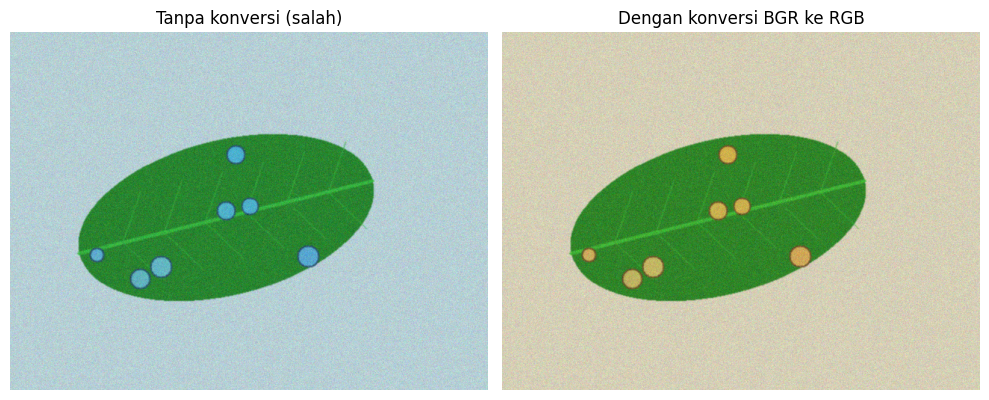

Gambar tersimpan: /content/drive/MyDrive/simuteh/hasil/b1_bgr_rgb.png


In [13]:
import os
import sys
import cv2
import numpy as np
import skimage
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/simuteh"
SRC_DIR = os.path.join(PROJECT_DIR, "src")
DATA_DIR = os.path.join(PROJECT_DIR, "data", "sintetis")
HASIL_DIR = os.path.join(PROJECT_DIR, "hasil")

os.makedirs(HASIL_DIR, exist_ok=True)

if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

from utils_cv import baca, tampil

print(
    "OpenCV", cv2.__version__,
    "| NumPy", np.__version__,
    "| scikit-image", skimage.__version__
)

img_path = os.path.join(DATA_DIR, "citra", "teh_041.png")
img = baca(img_path)

print("shape:", img.shape, "dtype:", img.dtype)
print("min-maks:", img.min(), img.max())
print("piksel (y=100, x=200) dalam urutan BGR:", img[100, 200])

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Tanpa konversi (salah)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Dengan konversi BGR ke RGB")
plt.axis("off")

plt.tight_layout()

output_path = os.path.join(HASIL_DIR, "b1_bgr_rgb.png")
plt.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()

print("Gambar tersimpan:", output_path)

### Problem Statement SIMUTEH

Bagi petugas sortir daun teh yang mengalami kesulitan membedakan tingkat keparahan bercak pada daun secara konsisten, kami membangun SIMUTEH, yaitu sistem visi komputer yang menerima citra daun teh dan menghasilkan klasifikasi kondisi daun ke dalam tiga kelas, yaitu sehat, bercak ringan, dan bercak berat. Sistem ini diharapkan dapat membantu petugas melakukan penyortiran dengan lebih konsisten dan mengurangi kesalahan penilaian. Hasil klasifikasi tetap perlu dipertimbangkan bersama pemeriksaan petugas.


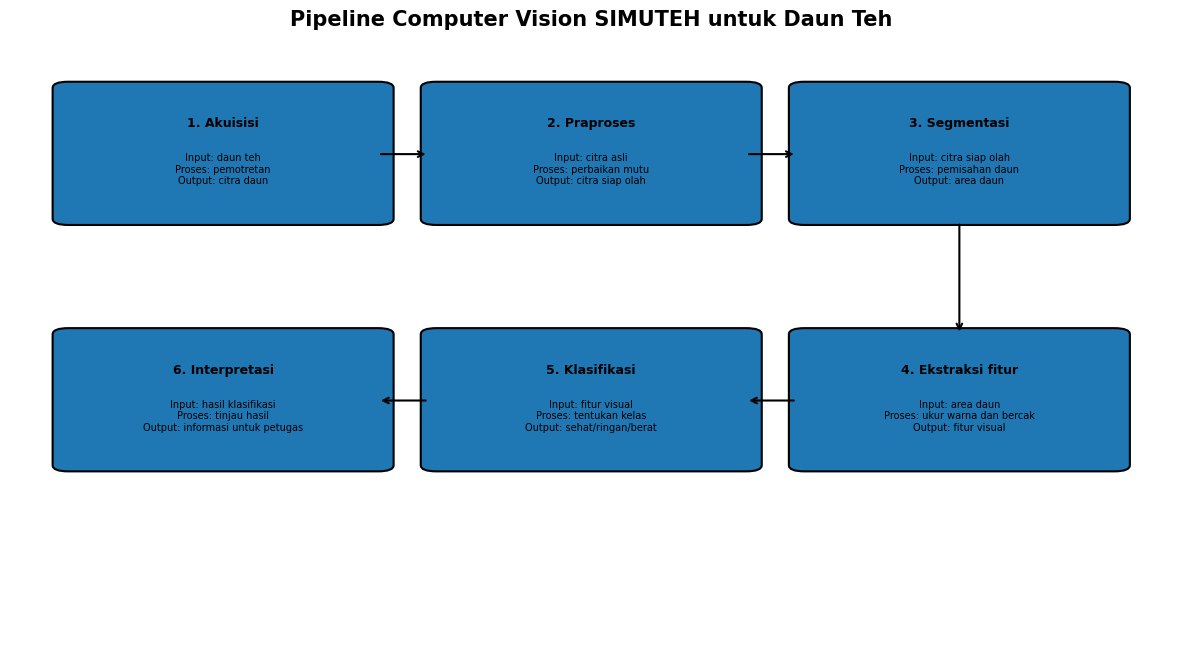

Diagram tersimpan: /content/drive/MyDrive/simuteh/hasil/b1_pipeline.png


In [14]:
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

PROJECT_DIR = "/content/drive/MyDrive/simuteh"
HASIL_DIR = os.path.join(PROJECT_DIR, "hasil")
os.makedirs(HASIL_DIR, exist_ok=True)

tahapan = [
    (
        "1. Akuisisi",
        "Input: daun teh\nProses: pemotretan\nOutput: citra daun"
    ),
    (
        "2. Praproses",
        "Input: citra asli\nProses: perbaikan mutu\nOutput: citra siap olah"
    ),
    (
        "3. Segmentasi",
        "Input: citra siap olah\nProses: pemisahan daun\nOutput: area daun"
    ),
    (
        "4. Ekstraksi fitur",
        "Input: area daun\nProses: ukur warna dan bercak\nOutput: fitur visual"
    ),
    (
        "5. Klasifikasi",
        "Input: fitur visual\nProses: tentukan kelas\nOutput: sehat/ringan/berat"
    ),
    (
        "6. Interpretasi",
        "Input: hasil klasifikasi\nProses: tinjau hasil\nOutput: informasi untuk petugas"
    )
]

fig, ax = plt.subplots(figsize=(15, 8))
ax.set_xlim(0, 3)
ax.set_ylim(0, 4)
ax.axis("off")

posisi = [
    (0.15, 2.8), (1.1, 2.8), (2.05, 2.8),
    (2.05, 1.2), (1.1, 1.2), (0.15, 1.2)
]

for i, ((judul, isi), (x, y)) in enumerate(zip(tahapan, posisi)):
    kotak = FancyBboxPatch(
        (x, y), 0.8, 0.85,
        boxstyle="round,pad=0.04",
        linewidth=1.5
    )
    ax.add_patch(kotak)
    ax.text(
        x + 0.4, y + 0.62, judul,
        ha="center", va="center",
        fontsize=9, fontweight="bold"
    )
    ax.text(
        x + 0.4, y + 0.32, isi,
        ha="center", va="center",
        fontsize=7
    )

# Panah tahap 1 sampai 3
for x in [0.95, 1.9]:
    ax.annotate(
        "", xy=(x + 0.13, 3.22), xytext=(x, 3.22),
        arrowprops=dict(arrowstyle="->", lw=1.5)
    )

# Panah dari tahap 3 turun ke tahap 4
ax.annotate(
    "", xy=(2.45, 2.05), xytext=(2.45, 2.78),
    arrowprops=dict(arrowstyle="->", lw=1.5)
)

# Panah tahap 4 ke 5 lalu 6
for x in [1.9, 0.95]:
    ax.annotate(
        "", xy=(x, 1.62), xytext=(x + 0.13, 1.62),
        arrowprops=dict(arrowstyle="->", lw=1.5)
    )

ax.set_title(
    "Pipeline Computer Vision SIMUTEH untuk Daun Teh",
    fontsize=15,
    fontweight="bold"
)

output_path = os.path.join(HASIL_DIR, "b1_pipeline.png")
plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print("Diagram tersimpan:", output_path)

In [16]:
import os
import sys
import cv2
import numpy as np
import skimage

PROJECT_DIR = "/content/drive/MyDrive/simuteh"
SRC_DIR = os.path.join(PROJECT_DIR, "src")

if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

from utils_cv import baca

img = baca(
    os.path.join(
        PROJECT_DIR,
        "data",
        "sintetis",
        "citra",
        "teh_041.png"
    )
)

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("scikit-image:", skimage.__version__)
print("Shape:", img.shape)
print("Dtype:", img.dtype)
print("Nilai minimum:", img.min())
print("Nilai maksimum:", img.max())
print("Piksel BGR:", img[100, 200])

OpenCV: 4.14.0
NumPy: 2.1.3
scikit-image: 0.25.2
Shape: (480, 640, 3)
Dtype: uint8
Nilai minimum: 0
Nilai maksimum: 255
Piksel BGR: [172 206 225]


### P1.1. Semantic Gap pada SIMUTEH

Semantic gap merupakan perbedaan antara informasi yang dipahami manusia dan informasi yang diterima komputer. Petugas sortir dapat melihat bentuk daun, warna, dan tingkat keparahan bercak secara langsung. Sementara itu, komputer menerima citra dalam bentuk larik angka yang mewakili intensitas piksel pada kanal warna.

Sebagai contoh, piksel pada koordinat (y=100, x=200) menghasilkan nilai BGR **[172 206 225]**. Nilai tersebut menunjukkan intensitas kanal biru, hijau, dan merah. Komputer tidak langsung memahami bahwa daun tersebut sehat atau terkena penyakit. Sistem perlu mengolah informasi visual untuk membantu menentukan kondisi daun.

### P1.2. Tiga Sumber Variasi Citra

Tiga sumber variasi yang dapat mengganggu SIMUTEH adalah pencahayaan, sudut pandang, dan derau serta latar belakang.

1. **Pencahayaan.** Cahaya yang terlalu gelap atau terang dapat mengubah nilai intensitas dan warna daun. Tahap praproses dapat membantu mengurangi pengaruh variasi pencahayaan sebelum fitur dihitung.

2. **Sudut pandang.** Perbedaan posisi kamera dapat mengubah bentuk daun yang terlihat. Tahap akuisisi perlu menjaga posisi pengambilan citra. Jika diperlukan, praproses dapat membantu menyesuaikan orientasi citra.

3. **Derau dan latar belakang.** Gangguan sensor dan pola latar dapat mengganggu pengamatan terhadap bercak. Tahap praproses dapat mengurangi derau, sedangkan segmentasi membantu memisahkan daun dari latar belakang.

### P1.3. Perbedaan BGR dan RGB

OpenCV membaca citra berwarna dengan urutan kanal BGR, sedangkan Matplotlib menganggap urutan kanalnya RGB. Jika citra BGR langsung ditampilkan menggunakan Matplotlib, kanal biru dan merah dapat tertukar sehingga warna terlihat berbeda.

Kesalahan tersebut dapat memengaruhi perhitungan fitur warna jika program menggunakan kanal yang keliru. Akibatnya, sistem dapat menghasilkan fitur yang tidak sesuai dengan warna sebenarnya dan meningkatkan risiko kesalahan klasifikasi. Karena itu, pengolahan dan penampilan citra perlu memperhatikan urutan kanal warna.

### P1.4. Keadilan dan Amanah

Jika daun sehat diklasifikasikan sebagai bercak berat, petani atau pengelola kebun dapat dirugikan karena daun yang masih baik berpotensi ditolak. Sebaliknya, jika daun dengan bercak berat diklasifikasikan sebagai sehat, daun yang bermasalah dapat lolos penyortiran dan menurunkan mutu hasil.

Prinsip keadilan mengharuskan sistem mengurangi kesalahan yang merugikan pihak terkait. Prinsip amanah mengharuskan pengembang menjelaskan keterbatasan sistem dan tidak menganggap hasil klasifikasi selalu benar. Oleh karena itu, hasil SIMUTEH sebaiknya digunakan sebagai alat bantu, sedangkan pemeriksaan petugas tetap diperlukan.


In [15]:
import os

PROJECT_DIR = "/content/drive/MyDrive/simuteh"

file_penting = [
    "src/buat_dataset_sintetis.py",
    "src/utils_cv.py",
    "data/sintetis/label.csv",
    "hasil/b1_bgr_rgb.png",
    "hasil/b1_pipeline.png"
]

print("PEMERIKSAAN HASIL B1")

for file in file_penting:
    path = os.path.join(PROJECT_DIR, file)
    print(
        "[OK]" if os.path.exists(path) else "[BELUM ADA]",
        file
    )

for folder in [
    "data/sintetis/citra",
    "data/sintetis/bersih",
    "data/sintetis/mask_daun",
    "data/sintetis/mask_bercak"
]:
    path = os.path.join(PROJECT_DIR, folder)
    jumlah = len([
        f for f in os.listdir(path)
        if f.lower().endswith(".png")
    ]) if os.path.isdir(path) else 0

    print(f"{folder}: {jumlah} citra")

PEMERIKSAAN HASIL B1
[OK] src/buat_dataset_sintetis.py
[OK] src/utils_cv.py
[OK] data/sintetis/label.csv
[OK] hasil/b1_bgr_rgb.png
[OK] hasil/b1_pipeline.png
data/sintetis/citra: 60 citra
data/sintetis/bersih: 60 citra
data/sintetis/mask_daun: 60 citra
data/sintetis/mask_bercak: 60 citra


### Tabel Risiko Responsible Computer Vision SIMUTEH

| Aspek             | Risiko pada SIMUTEH                                                                                    | Mitigasi Awal                                                                                |
| ----------------- | ------------------------------------------------------------------------------------------------------ | -------------------------------------------------------------------------------------------- |
| Privasi citra     | Citra dapat memuat informasi lokasi atau aktivitas kebun yang tidak diperlukan.                        | Batasi pengambilan citra pada objek yang diperlukan dan hindari menyimpan informasi pribadi. |
| Bias dan keadilan | Sistem dapat menghasilkan prediksi berbeda ketika pencahayaan atau kondisi daun berubah.               | Uji sistem pada berbagai kondisi pencahayaan dan periksa kesalahan klasifikasi setiap kelas. |
| Transparansi      | Petugas tidak mengetahui alasan sistem memberikan hasil klasifikasi tertentu.                          | Dokumentasikan metode, hasil pengujian, dan keterbatasan sistem.                             |
| Keamanan data     | Dataset dan hasil pengujian dapat diubah atau diakses pihak yang tidak berwenang.                      | Batasi akses dan simpan salinan cadangan dataset serta kode.                                 |
| Dampak sosial     | Petugas dapat terlalu bergantung pada prediksi sehingga kesalahan sistem merugikan proses penyortiran. | Jadikan sistem sebagai alat bantu dan pertahankan pemeriksaan petugas.                       |
| Keterlacakan      | Kesalahan prediksi sulit ditelusuri jika versi data dan kode tidak dicatat.                            | Catat sumber data, label, versi kode, dan hasil evaluasi.                                    |


In [17]:
%%writefile /content/drive/MyDrive/simuteh/requirements.txt
opencv-python
numpy
matplotlib
scikit-image
pandas
pillow

Writing /content/drive/MyDrive/simuteh/requirements.txt


In [18]:
import cv2
import numpy as np
import matplotlib
import skimage
import pandas as pd
import PIL

PROJECT_DIR = "/content/drive/MyDrive/simuteh"

versi = f"""opencv-python=={cv2.__version__}
numpy=={np.__version__}
matplotlib=={matplotlib.__version__}
scikit-image=={skimage.__version__}
pandas=={pd.__version__}
pillow=={PIL.__version__}
"""

with open(f"{PROJECT_DIR}/requirements.txt", "w") as f:
    f.write(versi)

print(versi)

opencv-python==4.14.0
numpy==2.1.3
matplotlib==3.10.0
scikit-image==0.25.2
pandas==2.2.3
pillow==11.3.0

